# Week 11: Customer Segmentation & Prediction
**Goal:** segment customers, compare clustering algorithms, build segment-specific churn predictors, tune models, and translate results into business actions.

> Run all cells from top to bottom. The notebook expects `segmentation_data.csv` in the same folder. It excludes `CustomerID` from learning and excludes `Churn` from clustering to avoid target leakage.

## 1. Imports and reproducibility

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)


## 2. Load data and validate quality

In [2]:
from pathlib import Path
data_path = Path("data/customer_churn.csv") if Path("data/customer_churn.csv").exists() else Path("segmentation_data.csv")
df = pd.read_csv(data_path)
print("Shape:", df.shape)
display(df.head())
display(df.isna().sum().rename("missing_values").to_frame())
print("Duplicate rows:", df.duplicated().sum())
print("Target distribution:")
display(df["Churn"].value_counts(dropna=False).rename("count").to_frame())
assert "Churn" in df.columns, "Expected target column 'Churn'."
assert len(df) > 0, "Dataset is empty."


Shape: (500, 9)


,CustomerID,Tenure,MonthlyCharges,TotalCharges,Contract,PaymentMethod,PaperlessBilling,SeniorCitizen,Churn
0,C00001,6,64,1540,One year,Credit Card,No,1,0
1,C00002,21,113,1753,Month-to-month,Electronic Check,Yes,1,0
2,C00003,27,31,1455,Two year,Credit Card,No,1,0
3,C00004,53,29,7150,Month-to-month,Electronic Check,No,1,0
4,C00005,16,185,1023,One year,Electronic Check,No,1,0


,missing_values
CustomerID,0
Tenure,0
MonthlyCharges,0
TotalCharges,0
Contract,0
PaymentMethod,0
PaperlessBilling,0
SeniorCitizen,0
Churn,0


Duplicate rows: 0
Target distribution:


,count
Churn,
0,447
1,53


## 3. Prepare clustering features (no target leakage)

In [3]:
target_col = "Churn"
id_cols = [c for c in df.columns if c.lower() in ("customerid", "customer_id", "id")]
X_raw = df.drop(columns=[target_col] + id_cols, errors="ignore")
numeric_cols = X_raw.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_raw.select_dtypes(exclude=np.number).columns.tolist()
num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
cluster_preprocessor = ColumnTransformer([("num", num_pipe, numeric_cols), ("cat", cat_pipe, categorical_cols)])
X_cluster = cluster_preprocessor.fit_transform(X_raw)
print("Clustering matrix shape:", X_cluster.shape)


Clustering matrix shape: (500, 12)


## 4. K-Means and Elbow method

,k,inertia
0,2,2406.523536
1,3,2196.764280
2,4,2013.920615
3,5,1883.607062
4,6,1772.395604


,k,silhouette
0,2,0.172872
1,3,0.146420
2,4,0.141203
3,5,0.137058
4,6,0.135301


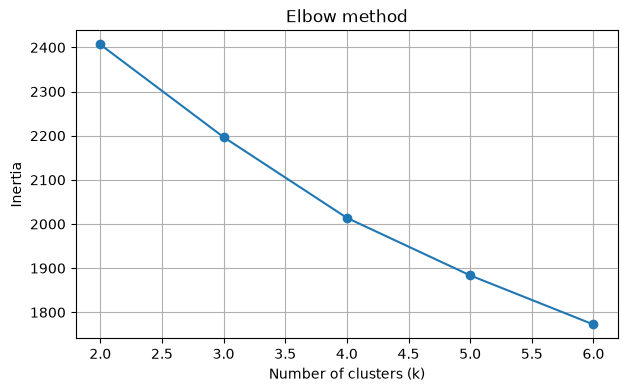

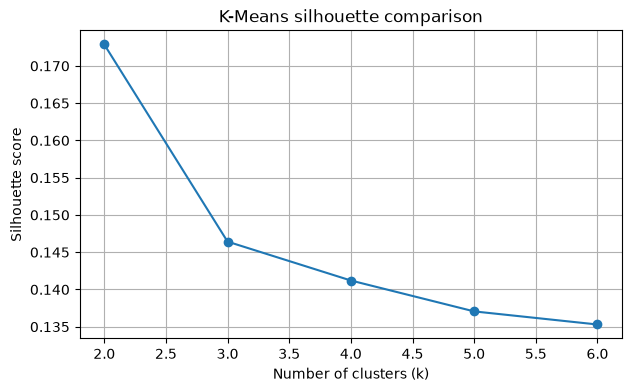

In [4]:
elbow_rows, silhouette_rows = [], []
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_cluster)
    elbow_rows.append({"k": k, "inertia": km.inertia_})
    silhouette_rows.append({"k": k, "silhouette": silhouette_score(X_cluster, labels)})
elbow_df = pd.DataFrame(elbow_rows)
silhouette_df = pd.DataFrame(silhouette_rows)
display(elbow_df); display(silhouette_df)
plt.figure(figsize=(7,4)); plt.plot(elbow_df["k"], elbow_df["inertia"], marker="o"); plt.xlabel("Number of clusters (k)"); plt.ylabel("Inertia"); plt.title("Elbow method"); plt.grid(True); plt.show()
plt.figure(figsize=(7,4)); plt.plot(silhouette_df["k"], silhouette_df["silhouette"], marker="o"); plt.xlabel("Number of clusters (k)"); plt.ylabel("Silhouette score"); plt.title("K-Means silhouette comparison"); plt.grid(True); plt.show()


**Choice:** use k=3 for the main analysis because the internship brief requires 3+ segment-specific models. Review the elbow and silhouette plots rather than treating k=3 as universally optimal.

## 5. Compare K-Means, Hierarchical clustering, and DBSCAN

In [5]:
kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans.fit_predict(X_cluster)
hier_labels = AgglomerativeClustering(n_clusters=3).fit_predict(X_cluster)
dbscan_labels = DBSCAN(eps=1.8, min_samples=8).fit_predict(X_cluster)
def clustering_summary(name, labels, X):
    labels = np.asarray(labels)
    mask = labels != -1
    n_clusters = len(set(labels[mask]))
    score = np.nan
    if n_clusters >= 2 and mask.sum() > n_clusters:
        try: score = silhouette_score(X[mask], labels[mask])
        except ValueError: pass
    return {"Algorithm": name, "Clusters_excluding_noise": n_clusters,
            "Noise_percent": round((labels == -1).mean()*100, 2),
            "Silhouette_score": round(score, 4) if pd.notna(score) else np.nan}
cluster_comparison = pd.DataFrame([
    clustering_summary("K-Means (k=3)", kmeans_labels, X_cluster),
    clustering_summary("Hierarchical (k=3)", hier_labels, X_cluster),
    clustering_summary("DBSCAN", dbscan_labels, X_cluster)
])
display(cluster_comparison)


,Algorithm,Clusters_excluding_noise,Noise_percent,Silhouette_score
0,K-Means (k=3),3,0.0,0.1464
1,Hierarchical (k=3),3,0.0,0.1149
2,DBSCAN,2,0.6,0.1735


## 6. Profile and name the K-Means segments

In [6]:
analysis_df = df.copy()
analysis_df["SegmentID"] = kmeans_labels + 1
agg_dict = {"SegmentID": "size"}
for col in ["Tenure", "MonthlyCharges", "TotalCharges", "Churn"]:
    if col in analysis_df.columns:
        agg_dict[col] = "mean"
profiles = analysis_df.groupby("SegmentID").agg(agg_dict).rename(columns={"SegmentID":"Customers"}).reset_index()
profiles = profiles.rename(columns={"Tenure":"AvgTenure","MonthlyCharges":"AvgMonthlyCharges","TotalCharges":"AvgTotalCharges","Churn":"ChurnRate"})
profiles["SharePercent"] = profiles["Customers"] / len(analysis_df) * 100
tenure_median = profiles["AvgTenure"].median() if "AvgTenure" in profiles else 0
charge_median = profiles["AvgMonthlyCharges"].median() if "AvgMonthlyCharges" in profiles else 0
def assign_name(row):
    long_tenure = row.get("AvgTenure", 0) >= tenure_median
    high_charge = row.get("AvgMonthlyCharges", 0) >= charge_median
    if long_tenure and high_charge: return "Established High-Value"
    if not long_tenure and high_charge: return "Newer High-Charge"
    if long_tenure: return "Long-Tenure Value"
    return "Early-Stage Customers"
profiles["SegmentName"] = profiles.apply(assign_name, axis=1)
profiles["ChurnRatePercent"] = profiles["ChurnRate"] * 100
analysis_df = analysis_df.merge(profiles[["SegmentID","SegmentName"]], on="SegmentID", how="left")
display(profiles)


,SegmentID,Customers,AvgTenure,AvgMonthlyCharges,AvgTotalCharges,ChurnRate,SharePercent,SegmentName,ChurnRatePercent
0,1,114,39.535088,97.833333,6239.807018,0.087719,22.8,Long-Tenure Value,8.771930
1,2,249,35.702811,108.144578,4274.975904,0.100402,49.8,Established High-Value,10.040161
2,3,137,35.540146,136.766423,2504.627737,0.131387,27.4,Newer High-Charge,13.138686


## 7. Train a separate Random Forest per segment + GridSearchCV

In [7]:
metric_rows, importance_rows = [], []
for _, seg in profiles.iterrows():
    sid = int(seg["SegmentID"])
    part = analysis_df[analysis_df["SegmentID"] == sid].copy()
    X = part.drop(columns=["Churn","SegmentID","SegmentName"] + id_cols, errors="ignore")
    y = part["Churn"].astype(int)
    nums = X.select_dtypes(include=np.number).columns.tolist()
    cats = X.select_dtypes(exclude=np.number).columns.tolist()
    prep = ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median"))]), nums),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cats)
    ])
    result = {"SegmentID":sid,"SegmentName":seg["SegmentName"],"Samples":len(part),
              "Positive_Churn":int(y.sum()),"Negative_Churn":int((y==0).sum()),
              "Accuracy":np.nan,"Precision":np.nan,"Recall":np.nan,"F1":np.nan,"ROC_AUC":np.nan,
              "Best_Params":"Not tuned: insufficient samples or class diversity"}
    if len(part) >= 12 and y.nunique() == 2 and y.value_counts().min() >= 4:
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)
        pipe = Pipeline([("prep", prep), ("model", RandomForestClassifier(random_state=RANDOM_STATE, class_weight="balanced"))])
        cv = min(3, int(y_train.value_counts().min()))
        search = GridSearchCV(pipe, {"model__n_estimators":[100,200], "model__max_depth":[None,5,10], "model__min_samples_leaf":[1,2]}, scoring="f1", cv=cv, n_jobs=-1)
        search.fit(X_train, y_train)
        model = search.best_estimator_
        pred = model.predict(X_test)
        proba = model.predict_proba(X_test)[:,1]
        result.update({"Accuracy":accuracy_score(y_test,pred),"Precision":precision_score(y_test,pred,zero_division=0),
                       "Recall":recall_score(y_test,pred,zero_division=0),"F1":f1_score(y_test,pred,zero_division=0),
                       "ROC_AUC":roc_auc_score(y_test,proba),"Best_Params":str(search.best_params_)})
        try:
            fn = model.named_steps["prep"].get_feature_names_out()
            for feature, imp in zip(fn, model.named_steps["model"].feature_importances_):
                importance_rows.append({"SegmentID":sid,"SegmentName":seg["SegmentName"],"Feature":feature,"Importance":imp})
        except Exception: pass
    metric_rows.append(result)
metrics = pd.DataFrame(metric_rows)
display(metrics)


,SegmentID,SegmentName,Samples,Positive_Churn,Negative_Churn,Accuracy,Precision,Recall,F1,ROC_AUC,Best_Params
0,1,Long-Tenure Value,114,10,104,0.931034,0.666667,0.666667,0.666667,0.961538,"{'model__max_depth': None, 'model__min_samples..."
1,2,Established High-Value,249,25,224,0.984127,1.000000,0.833333,0.909091,0.994152,"{'model__max_depth': None, 'model__min_samples..."
2,3,Newer High-Charge,137,18,119,0.971429,0.833333,1.000000,0.909091,1.000000,"{'model__max_depth': None, 'model__min_samples..."


### Metric interpretation
- **Accuracy:** fraction of predictions that are correct.
- **Precision:** among customers predicted to churn, fraction who actually churned.
- **Recall:** among actual churners, fraction identified by the model.
- **F1:** harmonic mean of precision and recall.
- **ROC-AUC:** ranking quality across thresholds; meaningful only when the test split contains both classes.

Metrics are reported as unavailable when the segment is too small or lacks enough examples of both classes. Do not invent a score for those cases.

## 8. Feature importance

,SegmentID,SegmentName,Feature,Importance
0,1,Long-Tenure Value,num__Tenure,0.550649
1,1,Long-Tenure Value,num__MonthlyCharges,0.101253
2,1,Long-Tenure Value,num__TotalCharges,0.079405
8,1,Long-Tenure Value,cat__PaymentMethod_Credit Card,0.072491
6,1,Long-Tenure Value,cat__Contract_Two year,0.067082
4,1,Long-Tenure Value,cat__Contract_Month-to-month,0.056003
7,1,Long-Tenure Value,cat__PaymentMethod_Bank Transfer,0.019977
11,1,Long-Tenure Value,cat__PaperlessBilling_Yes,0.017442
5,1,Long-Tenure Value,cat__Contract_One year,0.014183
9,1,Long-Tenure Value,cat__PaymentMethod_Electronic Check,0.010990


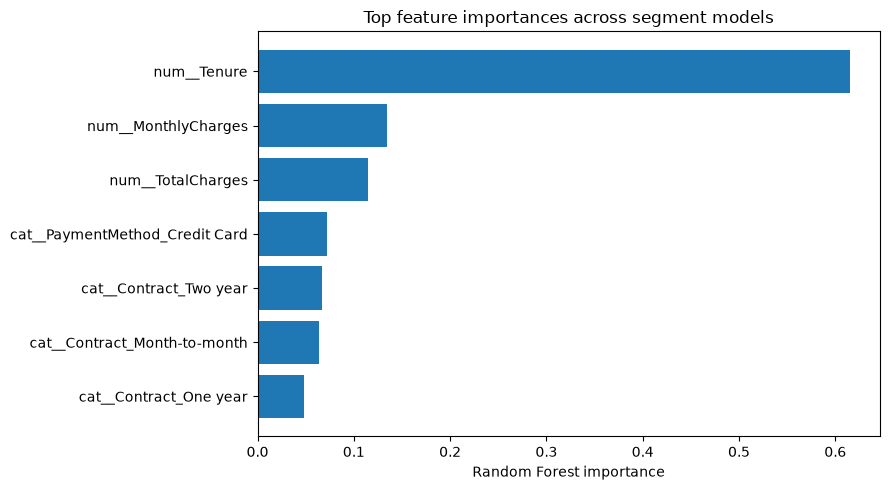

In [8]:
importance_df = pd.DataFrame(importance_rows)
if not importance_df.empty:
    display(importance_df.sort_values(["SegmentID","Importance"], ascending=[True,False]).groupby("SegmentID").head(10))
    top = importance_df.sort_values("Importance", ascending=False).head(15)
    plt.figure(figsize=(9,5)); plt.barh(top["Feature"], top["Importance"]); plt.gca().invert_yaxis()
    plt.xlabel("Random Forest importance"); plt.title("Top feature importances across segment models"); plt.tight_layout(); plt.show()
else:
    print("No segment model had enough data/class diversity to produce feature importances.")


## 9. Business recommendations

In [9]:
recommendations = []
for _, r in profiles.iterrows():
    churn_rate = r.get("ChurnRatePercent", 0)
    action = ("Prioritize retention: proactive outreach, service check-ins, and a time-limited loyalty offer; test against a holdout group."
              if churn_rate >= profiles["ChurnRatePercent"].median()
              else "Protect loyalty: reinforce value, recommend relevant add-ons, and use periodic satisfaction checks instead of blanket discounts.")
    if r.get("AvgTenure", 0) < profiles["AvgTenure"].median():
        action += " Add an early-life onboarding journey during the first 90 days."
    if r.get("AvgMonthlyCharges", 0) >= profiles["AvgMonthlyCharges"].median():
        action += " Test premium support/value bundles; verify margin before discounting."
    recommendations.append({"SegmentID":int(r["SegmentID"]),"SegmentName":r["SegmentName"],"Recommendation":action})
recommendations_df = pd.DataFrame(recommendations)
display(recommendations_df)


,SegmentID,SegmentName,Recommendation
0,1,Long-Tenure Value,"Protect loyalty: reinforce value, recommend re..."
1,2,Established High-Value,"Prioritize retention: proactive outreach, serv..."
2,3,Newer High-Charge,"Prioritize retention: proactive outreach, serv..."


## 10. Validation and export

In [10]:
assert analysis_df["SegmentID"].nunique() == 3, "Expected three K-Means segments."
assert analysis_df["SegmentID"].notna().all(), "Some rows have no segment assignment."
assert set(metrics["SegmentID"]) == set(profiles["SegmentID"]), "Expected one evaluation row per segment."
print("Validation passed: segment assignments and segment-level evaluation table are present.")
analysis_df.to_csv("segmentation_data.csv", index=False)
profiles.to_csv("segment_profiles_output.csv", index=False)
metrics.to_csv("model_evaluation_results.csv", index=False)
cluster_comparison.to_csv("clustering_comparison.csv", index=False)
importance_df.to_csv("feature_importance.csv", index=False)
recommendations_df.to_csv("business_recommendations.csv", index=False)
print("Exported project result CSV files.")


Validation passed: segment assignments and segment-level evaluation table are present.
Exported project result CSV files.
